In [40]:

# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [41]:
# loading the dataset
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [42]:
# Display the first five rows
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [43]:
# Display the shape of the dataset
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [44]:
# Display all column names
print(df.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


In [45]:
#Display information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [46]:
# Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all'))


Statistical Summary:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [47]:
# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [48]:
# Data Cleaning and Handling Missing Values
df['TotalCharges'] = df['TotalCharges'].str.strip()

In [49]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce')

In [50]:
# Check missing values after conversion
print("Missing Values Before Treatment:")
print(df.isnull().sum())

Missing Values Before Treatment:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [51]:
# Fill missing TotalCharges with the median
df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].median())

In [52]:
# Remove customerID because it is only an identifier
df.drop('customerID', axis=1, inplace=True)

In [53]:
# Check missing values after treatment
print("\nMissing Values After Treatment:")
print(df.isnull().sum())


Missing Values After Treatment:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [54]:
# Encoding Categorical Variables
# Convert the target column Churn into numerical values
# Yes = 1 and No = 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [55]:
# Convert categorical columns into numerical columns
df = pd.get_dummies(df, drop_first=True, dtype=int)

In [56]:
# Display the first five rows after encoding
print("Dataset After Encoding:")
display(df.head())

Dataset After Encoding:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [57]:
# Display the updated dataset shape
print("\nUpdated Dataset Shape:", df.shape)


Updated Dataset Shape: (7043, 31)


In [58]:

# Separate Features and Target

# X contains all input features
X = df.drop('Churn', axis=1)

# y contains the target variable
y = df['Churn']

# Display the shapes of X and y
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 30)
Target Shape: (7043,)


In [59]:
# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)
# Display the shape of training and testing data
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 30)
Testing Features: (1409, 30)
Training Target: (5634,)
Testing Target: (1409,)


In [60]:
# Create the Random Forest Classification model
rf_model = RandomForestClassifier(n_estimators=100,random_state=42)


In [61]:
# Train the Random Forest model using training data
rf_model.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

In [62]:

# Make Predictions
# Predict customer churn using testing data
y_pred = rf_model.predict(X_test)

# Display the first 10 actual values
print("Actual Values:")
print(y_test[:10].values)

# Display the first 10 predicted values
print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 0 0 0 0 0 0 0 0 1]

Predicted Values:
[0 1 0 0 0 0 0 0 0 0]


In [63]:

#  Model Evaluation

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculate Precision
precision = precision_score(y_test, y_pred)

# Calculate Recall
recall = recall_score(y_test, y_pred)

# Calculate F1 Score
f1 = f1_score(y_test, y_pred)

# Display all evaluation metrics
print("Model Evaluation Results")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Evaluation Results
Accuracy: 0.7863733144073811
Precision: 0.6237288135593221
Recall: 0.4919786096256685
F1 Score: 0.5500747384155455

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.77      0.79      0.78      1409



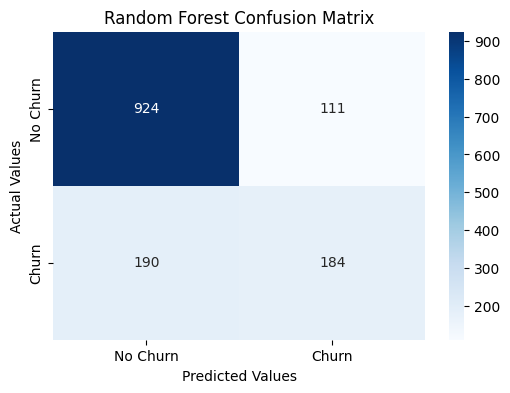

In [64]:

#  Confusion Matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix using a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

# Add chart labels and title
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Random Forest Confusion Matrix')

# Display the graph
plt.show()

In [65]:

# Bonus 1: Hyperparameter Tuning

# Import GridSearchCV
from sklearn.model_selection import GridSearchCV

# Define parameters for tuning
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

# Train using different parameter combinations
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best Parameters:", grid_search.best_params_)

# Display the best accuracy
print("Best Cross Validation Accuracy:", grid_search.best_score_)


Best Parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best Cross Validation Accuracy: 0.8031593894213703


In [66]:

# Evaluate the Best Tuned Random Forest Model

# Get the best model from GridSearchCV
best_model = grid_search.best_estimator_

# Make predictions using the tuned model
tuned_predictions = best_model.predict(X_test)

# Calculate evaluation metrics
print("Tuned Model Accuracy:",
      accuracy_score(y_test, tuned_predictions))

print("Tuned Model Precision:",
      precision_score(y_test, tuned_predictions))

print("Tuned Model Recall:",
      recall_score(y_test, tuned_predictions))

print("Tuned Model F1 Score:",
      f1_score(y_test, tuned_predictions))


Tuned Model Accuracy: 0.8005677785663591
Tuned Model Precision: 0.6576271186440678
Tuned Model Recall: 0.5187165775401069
Tuned Model F1 Score: 0.5799701046337817


In [67]:

# Bonus 2: Cross Validation

# Import cross_val_score
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross validation
cv_scores = cross_val_score(
    grid_search.best_estimator_,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Display cross validation scores
print("Cross Validation Scores:", cv_scores)

# Calculate average accuracy
print("Average Cross Validation Accuracy:", cv_scores.mean())


Cross Validation Scores: [0.81543922 0.80922804 0.79946761 0.78527063 0.78330373]
Average Cross Validation Accuracy: 0.7985418462697458


Top 10 Important Features:
tenure                            0.180062
TotalCharges                      0.167999
MonthlyCharges                    0.111611
InternetService_Fiber optic       0.073137
Contract_Two year                 0.062748
PaymentMethod_Electronic check    0.058690
OnlineSecurity_Yes                0.037537
Contract_One year                 0.036325
TechSupport_Yes                   0.023374
PaperlessBilling_Yes              0.022046
dtype: float64


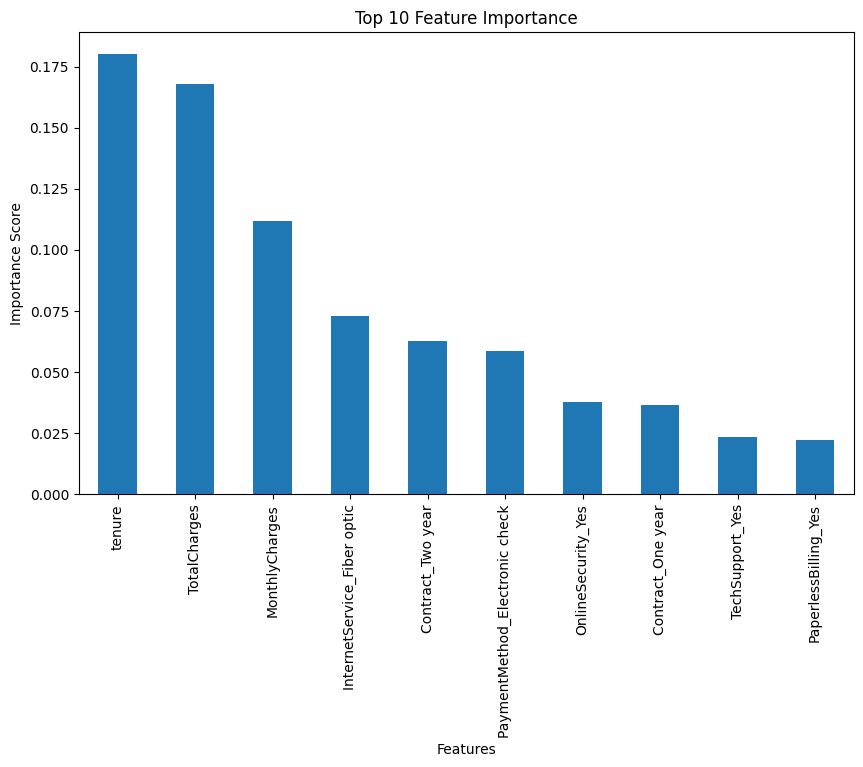

In [68]:
# Bonus 3: Feature Importance

# Get feature importance from the trained model
feature_importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
)

# Sort features by importance
feature_importance = feature_importance.sort_values(
    ascending=False
)

# Display the top 10 important features
print("Top 10 Important Features:")
print(feature_importance.head(10))

# Plot feature importance
plt.figure(figsize=(10, 6))
feature_importance.head(10).plot(kind='bar')

# Add chart title and labels
plt.title('Top 10 Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance Score')

plt.show()


In [69]:

# Bonus 4: Model Saving Using Joblib

# Import joblib
import joblib

# Save the best Random Forest model
joblib.dump(
    grid_search.best_estimator_,
    'random_forest_model.pkl'
)

# Display success message
print("Random Forest Model Saved Successfully!")

Random Forest Model Saved Successfully!


In [70]:

# Load the saved model
loaded_model = joblib.load('random_forest_model.pkl')

# Make predictions using the loaded model
saved_predictions = loaded_model.predict(X_test)

print("Saved Model Loaded Successfully!")
print("First 10 Predictions:", saved_predictions[:10])


Saved Model Loaded Successfully!
First 10 Predictions: [0 1 0 0 0 1 0 0 0 0]


## Conclusion

In this project, we successfully developed a **Random Forest Classification Model** to predict customer churn using the Telco Customer Churn dataset.

The dataset was preprocessed by handling missing values and encoding categorical variables. The data was divided into training and testing sets, and the Random Forest algorithm was used to train the model and make predictions.

The model was evaluated using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix. Hyperparameter tuning and Cross Validation were also performed to improve model performance and reliability.

Feature importance helped identify the factors that influence customer churn. The trained model was saved using Joblib for future use.

Overall, this project demonstrates how machine learning can help telecommunication companies predict customer churn and improve customer retention.